In [23]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import requests
from google.colab import drive

In [24]:
drive.mount("/content/drive/")

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [25]:
df = pd.read_parquet("/content/drive/MyDrive/Nino/finished_data/complete_df.parquet")
df.drop(columns=["death_label_t+3", "damage_label_t+3"], inplace=True)
df.columns

Index(['GEOID', 'date', 'damage_label', 'death_label', 'damage_antecedent_60',
       'damage_antecedent_12', 'deaths_antecedent_60', 'deaths_antecedent_12',
       'volumetric_soil_water_layer_3', 'precip_prior3', 'precip_prior6',
       'nino_3.4', 'year', 'population', 'pop_density', 'poverty_rate',
       'wind_speed', 'temperature_2m_anomaly',
       'dewpoint_temperature_2m_anomaly', 'hand_vulnerability', 'dist_coast_m',
       'pct_no_vehicle', 'lat', 'lon'],
      dtype='object')

In [26]:
# create training set [70%: 1996-2016], validation [15% 2017-2021], test [15%: 2022-present]
# another consideration is removing certain counties so that the model doesnt just fit to the county history

train = df[df["year"] < 2017].copy()
train.sort_values(by=["date", "GEOID"])

valid = df[(df["year"] > 2016) & (df["year"] < 2022)].copy()
valid.sort_values(by=["date", "GEOID"])

test = df[df["year"] > 2021].copy()
test.sort_values(by=["date", "GEOID"])

,GEOID,date,damage_label,death_label,damage_antecedent_60,damage_antecedent_12,deaths_antecedent_60,deaths_antecedent_12,volumetric_soil_water_layer_3,precip_prior3,...,pop_density,poverty_rate,wind_speed,temperature_2m_anomaly,dewpoint_temperature_2m_anomaly,hand_vulnerability,dist_coast_m,pct_no_vehicle,lat,lon
312,01001,2022-01,0.000000e+00,0.0,0.000000e+00,0.000000,0.00,0.0,0.492563,0.295365,...,38.799635,11.8,0.557608,-0.989717,-1.225046,0.275304,2.154338e+05,0.056405,32.534912,-86.642761
675,01003,2022-01,2.750192e+05,0.0,5.085309e+06,24752.355734,0.05,0.0,0.372783,0.189655,...,59.884446,12.4,0.863595,-1.078652,-1.583373,0.518318,0.000000e+00,0.034405,30.660276,-87.749781
1038,01005,2022-01,0.000000e+00,0.0,0.000000e+00,0.000000,0.00,0.0,0.426853,0.206437,...,10.785532,26.7,0.667264,-0.625540,-1.034392,0.265026,1.489900e+05,0.092423,31.869549,-85.393431
1401,01007,2022-01,0.000000e+00,0.0,0.000000e+00,0.000000,0.00,0.0,0.486200,0.270688,...,13.635680,20.0,0.404471,-1.071098,-1.499293,0.203039,2.747256e+05,0.059942,32.998616,-87.126462
1764,01009,2022-01,0.000000e+00,0.0,0.000000e+00,0.000000,0.00,0.0,0.495812,0.282209,...,35.621137,13.6,0.568811,-1.149509,-1.508803,0.166038,3.753407e+05,0.041553,33.980817,-86.567545
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1126746,56037,2025-10,0.000000e+00,0.0,1.485141e+04,0.000000,0.00,0.0,0.212235,0.053867,...,1.528304,9.1,2.820966,1.170442,2.034802,0.335714,1.076059e+06,0.024447,41.659225,-108.880362
1127109,56039,2025-10,0.000000e+00,0.0,0.000000e+00,0.000000,0.00,0.0,0.265027,0.092208,...,2.248115,5.4,0.828028,-0.170068,1.130895,0.183518,9.243763e+05,0.023804,43.932482,-110.589401
1127472,56041,2025-10,4.500000e+06,2.0,1.710521e+03,8552.605712,0.00,0.0,0.220415,0.083070,...,3.824631,10.7,2.057067,0.991310,2.140242,0.234355,1.018032e+06,0.039043,41.287375,-110.547558
1127835,56043,2025-10,0.000000e+00,0.0,0.000000e+00,0.000000,0.00,0.0,0.199375,0.066721,...,1.321459,11.4,0.521962,0.885000,2.250500,0.181252,1.129350e+06,0.050263,43.904991,-107.681956


In [27]:
# would usually impute, scale, and potentially fix categorical features
# i have no na values or cat features, and scaling is useless on trees/forests

In [28]:
X_train = train.drop(columns=["GEOID", "date", "damage_label", "death_label"]).copy()
y_train_damage = train["damage_label"].copy()
y_train_death = train["death_label"].copy()

X_valid = valid.drop(columns=["GEOID", "date", "damage_label", "death_label"]).copy()
y_valid_damage = valid["damage_label"].copy()
y_valid_death = valid["death_label"].copy()

X_test = test.drop(columns=["GEOID", "date", "damage_label", "death_label"]).copy()
y_test_damage = test["damage_label"].copy()
y_test_death = test["death_label"].copy()

In [29]:
# two-step hurdle model to handle the extreme sparsity and right skew of labels
# step 1: use forest classifier to determine the probability of a given instance being 0 or >0
# step 2: for all >0, use a regressor to predict the damage/death
# final: multiply step 1's probability by step 2's value for all

# step 1: hurdle classifier
from sklearn.ensemble import RandomForestClassifier

hurdle_clf = RandomForestClassifier(n_estimators=100, max_features="sqrt", max_leaf_nodes=16, n_jobs=-1, random_state=42)

# create the true or false label for whether the targets are 0 or 1
binary_damage_label = (y_train_damage > 0)
hurdle_clf.fit(X_train, binary_damage_label)

RandomForestClassifier(max_leaf_nodes=16, n_jobs=-1, random_state=42)

In [30]:
# evaluating hurdle classifier
from sklearn.metrics import confusion_matrix

y_train_damage_pred = hurdle_clf.predict(X_train)


cm = confusion_matrix(y_train_damage_pred, binary_damage_label)
cm
# first row is for the negative class (0s)
# 653,461 accurately classified; 126,662 incorrectly
# second row is positive class (>0)
# 391 incorrectly classified; 1702 correctly

array([[653461, 127662],
       [   391,   1702]])

In [31]:
# precision and recall
# precision is the accuracy of the positive predictions, ie if it says 100 instances are positive, what percent really were
# recall is the ratio of positive instances correctly classified, ie if there are ten true positives and only five are classified right,
#   then recall=0.5
from sklearn.metrics import precision_score, recall_score

precision = precision_score(y_train_damage_pred, binary_damage_label)
print(f"Precision:{precision}")

recall = recall_score(y_train_damage_pred, binary_damage_label)
print(f"Recall:{recall}")

Precision:0.013156674190655825
Recall:0.8131868131868132


In [32]:
# f1 score combines both precision and recall into a single representative valu
from sklearn.metrics import f1_score
f1 = f1_score(y_train_damage_pred, binary_damage_label)
f1

0.02589439892892733

In [33]:
# consider experimenting with a precision/recall curve

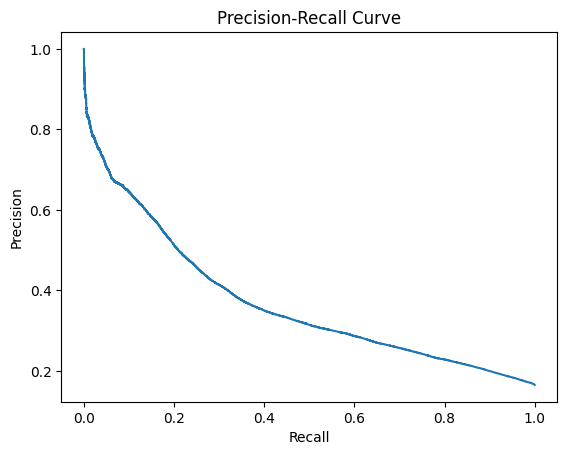

0.3690728053822715


In [34]:
# roc vs pr (precision-recall)
# roc curve plots FPR (false positive rate) against TPR (true positive rate)
# tpr works fine for sparse data, but fpr gets messed up
# since there are so many true negatives (0s), the fpr rate gets swallowed up and appears way lower than it should

# instead, we can use a pr-curve, which works bc it doesnt focus on the amount of true negatives
# only on recall and precision

# pr-curve uses proba scores that say the probability of each instance belonging to either class (so 2 cols that add to 1)
# we only keep the second col (proba of positive class) and use that to create precision recall values at every different threshold
# starting with the highest threshold at far left and decreasing as we go right
from sklearn.metrics import precision_recall_curve, auc

y_train_proba = hurdle_clf.predict_proba(X_train)[:, 1]
precision, recall, thresholds = precision_recall_curve(binary_damage_label, y_train_proba)
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

# want to maximize AUC (0-1)
print(auc(recall, precision))

# average precision is similar to pr-auc, also using the precision recall curve
# just calculates slightly differently, is more reliable, and (importantly) is used for tuning hyperparameters with the goal being to maximize it

In [ ]:
# now tune hyperparameters and test again
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit # time series split is to get around cross-val messing up time order

# time series split with 3 splits; make sure X_train is sorted by date first, then GEOID
tscv = TimeSeriesSplit(n_splits=3)
rnd_clf = RandomForestClassifier(n_jobs=1, random_state=42)

param_distributions = {
    "class_weight": ["balanced", {0:1, 1:10}, {0:1, 1:50}], # targets that are nonzero may be weighted heavier
    "max_depth": [15, 25, 35],
    "max_features": ["sqrt", 0.2, 0.5],
    "n_estimators": [100,200],
    "min_samples_leaf": [5, 20, 100], # the minimum number of samples needed to form a final leaf node
    "ccp_alpha": [0.0, 0.001] # used in very complex trees to prune certain nodes, reducing immediate accuracy but lessening overfitting/variance
}

rnd_search = RandomizedSearchCV(
    estimator=rnd_clf,
    param_distributions=param_distributions,
    n_iter=10, # number of different param combinations it can try
    cv=tscv,
    scoring="average_precision",
    n_jobs=-1,
    random_state=42,
    verbose=2 # give detailed info as it runs
)

rnd_search.fit(X_train, binary_damage_label)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
